In [3]:
import pandas as pd

file_path = "clinical_trials_raw_patient2trial_conditions.csv"
df = pd.read_csv("C:/Users/hemanathan/OneDrive/Desktop/guvi hcl/clinical disease analysis/clinical_trials_raw_patient2trial_conditions.csv")
display(df.head())

,source_condition_query,nct_id,title,official_title,brief_summary,conditions,interventions,overall_status,study_type,phase,sex,minimum_age,maximum_age,healthy_volunteers,eligibility_criteria,clinicaltrials_url
0,breast cancer,NCT03676114,Effect of Perioperative Low Dose Ketamine on P...,Effect of Perioperative Low Dose Ketamine on P...,Breast cancer patients often have perioperativ...,Breast Cancer,ketamine | Normal saline,UNKNOWN,INTERVENTIONAL,PHASE4,FEMALE,20 Years,65 Years,False,Inclusion Criteria:\n\n1. American Society of ...,https://clinicaltrials.gov/study/NCT03676114
1,breast cancer,NCT02941614,Implementing Systematic Distress Screening in ...,Implementing Systematic Distress Screening in ...,Many breast cancer patients experience psychol...,Breast Cancer,Distress screening,COMPLETED,OBSERVATIONAL,NaN,ALL,18 Years,NaN,False,Inclusion Criteria:\n\n* Newly diagnosed with ...,https://clinicaltrials.gov/study/NCT02941614
2,breast cancer,NCT04509063,Investigating Public Enthusiasm for Mammograph...,Investigating Public Enthusiasm for Mammograph...,"Based on an American study by Scherer et al., ...",Breast Neoplasm Female | Mammography Screening...,Information about hypothetical mammography scr...,COMPLETED,INTERVENTIONAL,NaN,FEMALE,44 Years,49 Years,True,Inclusion Criteria:\n\n* Residence: Central De...,https://clinicaltrials.gov/study/NCT04509063
3,breast cancer,NCT04327063,MIRs 04 : Interpectoral Nerve Block With Ropiv...,A Double-blind Randomized Trial of Interpector...,Compare the effect of ropivacaine versus place...,Malignant Neoplasm of Breast,Saline | Ropivacaine,COMPLETED,INTERVENTIONAL,PHASE3,FEMALE,18 Years,85 Years,False,Inclusion Criteria:\n\n1. Women with non-metas...,https://clinicaltrials.gov/study/NCT04327063
4,breast cancer,NCT06778863,A Study of CLSP-1025 in Adult Patients With So...,GUARDIAN-101: A Phase 1 Dose Escalation and Ex...,Phase 1 dose escalation and expansion study of...,Advanced Solid Tumor | Unresectable Solid Tumo...,CLSP-1025,RECRUITING,INTERVENTIONAL,PHASE1,ALL,18 Years,NaN,False,Key Inclusion Criteria:\n\n* Patients must be ...,https://clinicaltrials.gov/study/NCT06778863


In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 60337 entries, 0 to 60336
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   source_condition_query  60337 non-null  str   
 1   nct_id                  60337 non-null  str   
 2   title                   60337 non-null  str   
 3   official_title          59551 non-null  str   
 4   brief_summary           60337 non-null  str   
 5   conditions              60336 non-null  str   
 6   interventions           54276 non-null  str   
 7   overall_status          60337 non-null  str   
 8   study_type              60337 non-null  str   
 9   phase                   23336 non-null  str   
 10  sex                     60304 non-null  str   
 11  minimum_age             57121 non-null  str   
 12  maximum_age             28400 non-null  str   
 13  healthy_volunteers      58857 non-null  object
 14  eligibility_criteria    60326 non-null  str   
 15  clinicaltrial

In [6]:
df.describe()

,source_condition_query,nct_id,title,official_title,brief_summary,conditions,interventions,overall_status,study_type,phase,sex,minimum_age,maximum_age,healthy_volunteers,eligibility_criteria,clinicaltrials_url
count,60337,60337,60337,59551,60337,60336,54276,60337,60337,23336,60304,57121,28400,58857,60326,60337
unique,8,60337,60191,59272,60064,26460,46807,13,3,7,3,142,182,2,59872,60337
top,breast cancer,NCT03676114,COVID-19 Antibody Responses In Cystic Fibrosis,ACTIV-6: COVID-19 Outpatient Randomized Trial ...,Investigators are building an empirical eviden...,Breast Cancer,No intervention,COMPLETED,INTERVENTIONAL,PHASE2,ALL,18 Years,75 Years,False,No eligibility criteria,https://clinicaltrials.gov/study/NCT03676114
freq,16301,1,5,8,10,5060,161,33659,45548,7408,47436,39226,4100,45860,57,1


In [7]:
df.shape

(60337, 16)

In [9]:
df.isnull().sum()

source_condition_query        0
nct_id                        0
title                         0
official_title              786
brief_summary                 0
conditions                    1
interventions              6061
overall_status                0
study_type                    0
phase                     37001
sex                          33
minimum_age                3216
maximum_age               31937
healthy_volunteers         1480
eligibility_criteria         11
clinicaltrials_url            0
dtype: int64

In [10]:
df['official_title'] = df['official_title'].str.strip().str.lower()

In [12]:
print(df['official_title'].head())

# 2. Check for missing official titles
missing_titles = df['official_title'].isnull().sum()

0    effect of perioperative low dose ketamine on p...
1    implementing systematic distress screening in ...
2    investigating public enthusiasm for mammograph...
3    a double-blind randomized trial of interpector...
4    guardian-101: a phase 1 dose escalation and ex...
Name: official_title, dtype: str


In [23]:
# Check if brief_title exists and fill missing official titles with it
if 'brief_title' in df.columns:
    df['official_title'] = df['official_title'].fillna(df['brief_title'])

In [14]:
# Find the row where the 'conditions' column is null
null_row = df[df['conditions'].isnull()]
display(null_row)

,source_condition_query,nct_id,title,official_title,brief_summary,conditions,interventions,overall_status,study_type,phase,sex,minimum_age,maximum_age,healthy_volunteers,eligibility_criteria,clinicaltrials_url
9166,breast cancer,NCT03424473,Expanded Access Use of Tucatinib for HER2+ Met...,NaN,Physicians interested in requesting a single p...,NaN,Tucatinib,NO_LONGER_AVAILABLE,EXPANDED_ACCESS,NaN,NaN,NaN,NaN,NaN,Inclusion Criteria:\n\n\-\n\nExclusion Criteri...,https://clinicaltrials.gov/study/NCT03424473


In [15]:
# Drop rows where 'conditions' is missing
df = df.dropna(subset=['conditions'])

# Verify new row count
print("New total rows:", len(df))

New total rows: 60336


In [16]:
# 1. Check missing values in the interventions column
print("Missing Interventions Count:", df['interventions'].isnull().sum())

# 2. View sample intervention values
print("\nSample Interventions:")
display(df['interventions'].head(10))

# 3. Clean text (remove leading/trailing spaces & convert to lowercase)
df['interventions'] = df['interventions'].astype(str).str.strip().str.lower()

# 4. Count top 10 most common interventions
print("\nTop 10 Most Frequent Interventions:")
print(df['interventions'].value_counts().head(10))

Missing Interventions Count: 6061

Sample Interventions:


0                             ketamine | Normal saline
1                                   Distress screening
2    Information about hypothetical mammography scr...
3                                 Saline | Ropivacaine
4                                            CLSP-1025
5           Resistance Exercise | Flexibility Training
6                                      ultrasound scan
7                             Health education session
8     Ketamine | Pecs block | Nalbuphine | Paracetamol
9         Early palliative care | Routine hospice care
Name: interventions, dtype: str


Top 10 Most Frequent Interventions:
interventions
no intervention             256
exercise                    124
questionnaire               109
virtual reality              85
survey                       65
blood sample                 55
pulmonary rehabilitation     55
tocilizumab                  54
questionnaires               48
music therapy                43
Name: count, dtype: int64


In [17]:
df['interventions'] = df['interventions'].fillna('no intervention specified')

In [18]:
missing_phases = df['phase'].isnull().sum()
print("Missing phases count:", missing_phases)

Missing phases count: 37000


In [19]:
# Fill missing phases with a placeholder to preserve the row for NLP modeling
df['phase'] = df['phase'].fillna('unknown')

In [20]:
df['sex'] = df['sex'].fillna('all')

In [21]:
df['minimum_age'] = df['minimum_age'].fillna('not specified')
df['maximum_age'] = df['maximum_age'].fillna('not specified')

In [22]:
# 2. Standardize core text columns to lowercase and strip whitespace
text_columns = ['official_title', 'conditions', 'interventions', 'brief_summary']
for col in text_columns:
    df[col] = df[col].astype(str).str.strip().str.lower()

print("Preprocessing complete. Cleaned null counts:")
print(df[text_columns].isnull().sum())

Preprocessing complete. Cleaned null counts:
official_title    785
conditions          0
interventions       0
brief_summary       0
dtype: int64


In [24]:
df.isnull().sum()

source_condition_query       0
nct_id                       0
title                        0
official_title             785
brief_summary                0
conditions                   0
interventions                0
overall_status               0
study_type                   0
phase                        0
sex                          0
minimum_age                  0
maximum_age                  0
healthy_volunteers        1479
eligibility_criteria        11
clinicaltrials_url           0
dtype: int64

In [25]:
# Fallback to 'brief_summary' if official_title is missing, then use a default string if both are missing
df['official_title'] = df['official_title'].fillna(df['brief_summary']).fillna('not specified')

# Verify that there are zero nulls left in official_title
print("Remaining nulls in official_title:", df['official_title'].isnull().sum())

Remaining nulls in official_title: 0


In [26]:
# Check value counts including nulls
print(df['healthy_volunteers'].value_counts(dropna=False))

healthy_volunteers
False    45860
True     12997
NaN       1479
Name: count, dtype: int64


In [27]:
# Fill missing healthy_volunteers with a placeholder
df['healthy_volunteers'] = df['healthy_volunteers'].fillna('unknown')

# Verify zero nulls remain
print("Remaining nulls in healthy_volunteers:", df['healthy_volunteers'].isnull().sum())

Remaining nulls in healthy_volunteers: 0


In [28]:
# 1. Fill missing eligibility criteria with a placeholder
df['eligibility_criteria'] = df['eligibility_criteria'].fillna('not specified')

# 2. Standardize text (lowercase and strip whitespace) alongside other text columns
df['eligibility_criteria'] = df['eligibility_criteria'].astype(str).str.strip().str.lower()

# 3. Verify zero nulls remain
print("Remaining nulls in eligibility_criteria:", df['eligibility_criteria'].isnull().sum())

Remaining nulls in eligibility_criteria: 0


In [29]:
df.isnull().sum()

source_condition_query    0
nct_id                    0
title                     0
official_title            0
brief_summary             0
conditions                0
interventions             0
overall_status            0
study_type                0
phase                     0
sex                       0
minimum_age               0
maximum_age               0
healthy_volunteers        0
eligibility_criteria      0
clinicaltrials_url        0
dtype: int64

In [30]:
# 1. Check for exact duplicate rows across all columns
exact_dupes = df.duplicated().sum()
print("Exact duplicate rows:", exact_dupes)

# 2. Check for duplicate clinical trial IDs (nct_id should be unique)
if 'nct_id' in df.columns:
    id_dupes = df.duplicated(subset=['nct_id']).sum()
    print("Duplicate NCT IDs found:", id_dupes)

Exact duplicate rows: 0
Duplicate NCT IDs found: 0


In [31]:
# 1. View top disease categories and their counts
print("Top 15 Disease Categories:")
print(df['source_condition_query'].value_counts().head(15))

# 2. View percentage distribution
print("\nPercentage Distribution:")
print(df['source_condition_query'].value_counts(normalize=True).head(15) * 100)

Top 15 Disease Categories:
source_condition_query
breast cancer                            16300
type 2 diabetes                          11467
covid-19                                 10153
anxiety                                   9286
chronic obstructive pulmonary disease     6181
rheumatoid arthritis                      3637
glaucoma                                  2173
sickle cell anemia                        1139
Name: count, dtype: int64

Percentage Distribution:
source_condition_query
breast cancer                            27.015381
type 2 diabetes                          19.005237
covid-19                                 16.827433
anxiety                                  15.390480
chronic obstructive pulmonary disease    10.244299
rheumatoid arthritis                      6.027910
glaucoma                                  3.601498
sickle cell anemia                        1.887762
Name: proportion, dtype: float64


C:\Users\hemanathan\AppData\Local\Temp\ipykernel_8428\2989366720.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_categories.values, y=top_categories.index, palette='Blues_r')


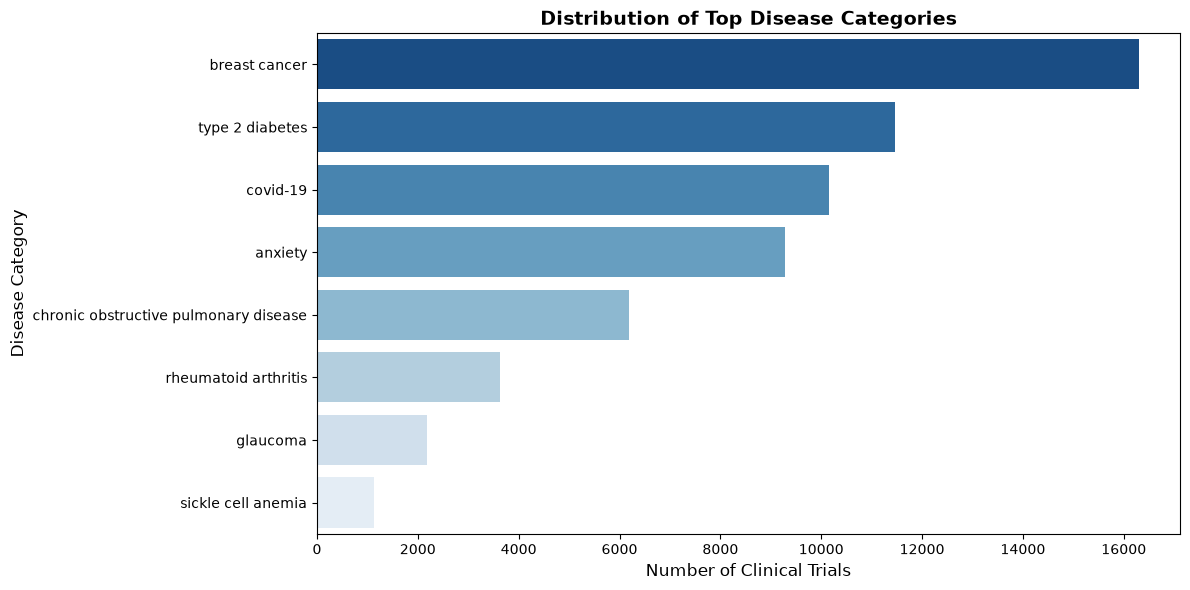

In [32]:
#Visualize Disease Category Distribution (Bar Chart)

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
top_categories = df['source_condition_query'].value_counts().head(12)

sns.barplot(x=top_categories.values, y=top_categories.index, palette='Blues_r')
plt.title('Distribution of Top Disease Categories', fontsize=14, fontweight='bold')
plt.xlabel('Number of Clinical Trials', fontsize=12)
plt.ylabel('Disease Category', fontsize=12)
plt.tight_layout()
plt.show()

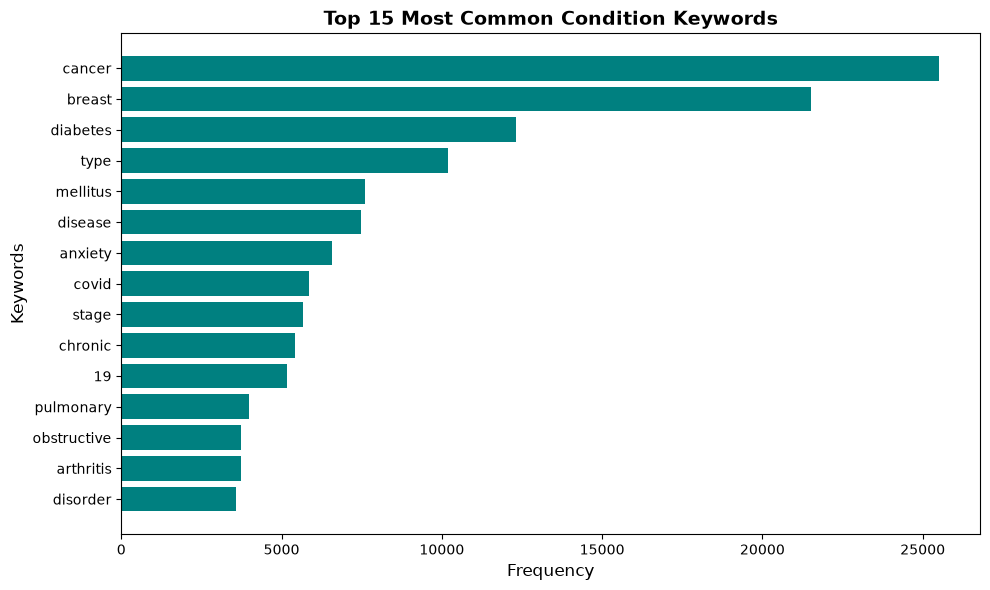

In [34]:
# Visualize Top Keywords and Conditions (Bar Chart of Frequencies)

from sklearn.feature_extraction.text import CountVectorizer

# Extract top unigrams from conditions
vectorizer = CountVectorizer(stop_words='english', max_features=15)
X_counts = vectorizer.fit_transform(df['conditions'].fillna(''))
keyword_freq = pd.DataFrame({
    'Keyword': vectorizer.get_feature_names_out(),
    'Frequency': X_counts.toarray().sum(axis=0)
}).sort_values(by='Frequency', ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(keyword_freq['Keyword'], keyword_freq['Frequency'], color='teal')
plt.title('Top 15 Most Common Condition Keywords', fontsize=14, fontweight='bold')
plt.xlabel('Frequency', fontsize=12)
plt.ylabel('Keywords', fontsize=12)
plt.tight_layout()
plt.show()

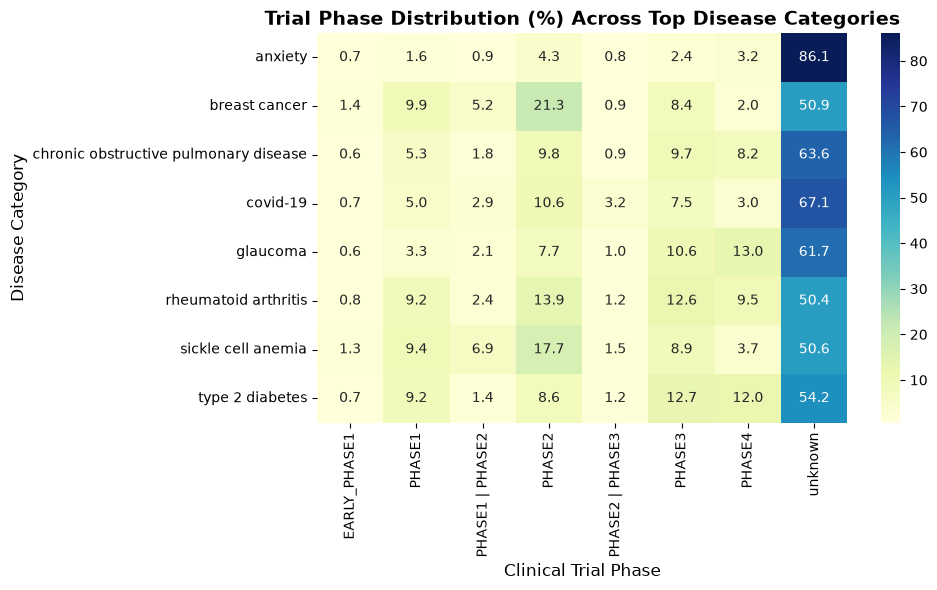

In [35]:
# Create a cross-tabulation of disease categories vs trial phase percentages
if 'phase' in df.columns:
    phase_category_crosstab = pd.crosstab(df['source_condition_query'], df['phase'], normalize='index') * 100
    
    plt.figure(figsize=(10, 6))
    sns.heatmap(phase_category_crosstab.head(8), annot=True, cmap='YlGnBu', fmt='.1f')
    plt.title('Trial Phase Distribution (%) Across Top Disease Categories', fontsize=14, fontweight='bold')
    plt.xlabel('Clinical Trial Phase', fontsize=12)
    plt.ylabel('Disease Category', fontsize=12)
    plt.tight_layout()
    plt.show()

C:\Users\hemanathan\AppData\Local\Temp\ipykernel_8428\1425099282.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=subset_df, x='summary_word_count', y='source_condition_query', palette='Set2')


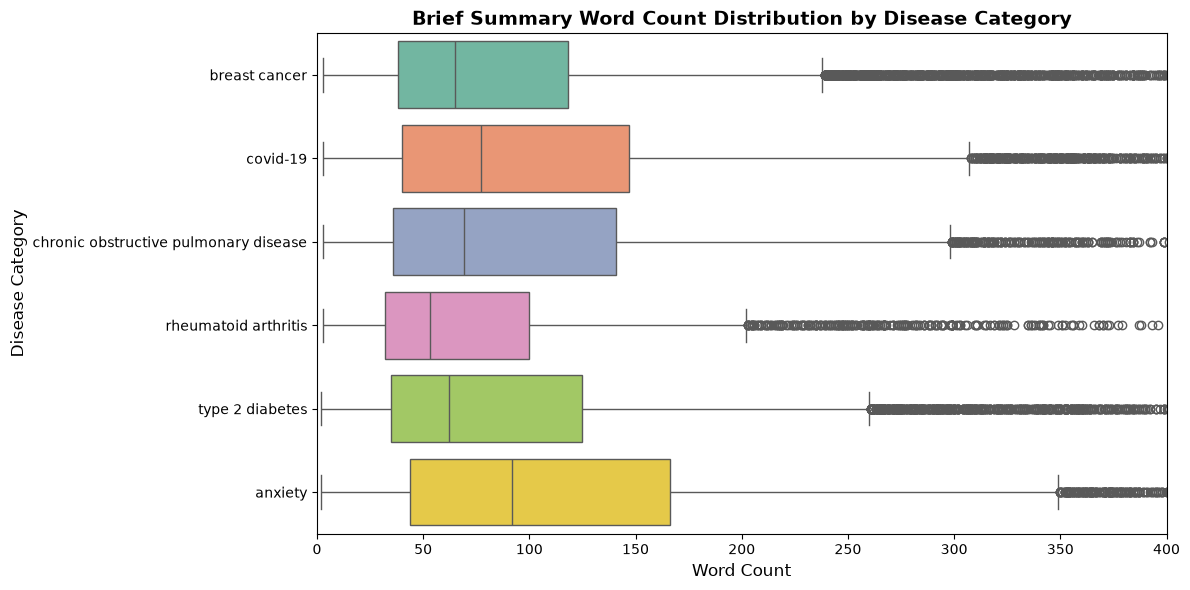

In [37]:
# Visualize Relationships Summary Lengths across Categories (Box Plot)



df['summary_word_count'] = df['brief_summary'].apply(lambda x: len(str(x).split()))

# Look at top 6 categories for a clean boxplot comparison
top_6 = df['source_condition_query'].value_counts().head(6).index
subset_df = df[df['source_condition_query'].isin(top_6)]

plt.figure(figsize=(12, 6))
sns.boxplot(data=subset_df, x='summary_word_count', y='source_condition_query', palette='Set2')
plt.title('Brief Summary Word Count Distribution by Disease Category', fontsize=14, fontweight='bold')
plt.xlabel('Word Count', fontsize=12)
plt.ylabel('Disease Category', fontsize=12)
plt.xlim(0, 400) # Zooming in for readability
plt.tight_layout()
plt.show()

In [38]:
df.to_csv('cleaned_data.csv', index=False)

In [1]:
import nltk

nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
print("All NLTK packages downloaded successfully!")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\hemanathan\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\hemanathan\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\hemanathan\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\hemanathan\AppData\Roaming\nltk_data...


All NLTK packages downloaded successfully!


In [3]:
import pandas as pd

# Load your dataset (use your actual CSV filename here, such as 'cleaned_clinical_trials.csv' or your original file)
df = pd.read_csv('cleaned_data.csv')

print("Dataset loaded successfully! Shape:", df.shape)

Dataset loaded successfully! Shape: (60336, 17)


In [4]:
#Tokenization, Stop Word Removal, Punctuation Cleaning, and Lemmatization

import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

# Download necessary NLTK assets (run once)
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    # 1. Remove punctuation and special characters (keep only letters and spaces)
    text = re.sub(r'[^a-zA-Z\s]', '', str(text))
    
    # 2. Tokenize text into individual words & convert to lowercase
    tokens = word_tokenize(text.lower())
    
    # 3. Remove stop words, short words, and apply lemmatization
    cleaned_tokens = [
        lemmatizer.lemmatize(token) 
        for token in tokens 
        if token not in stop_words and len(token) > 2
    ]
    
    # Join tokens back into a single cleaned string
    return ' '.join(cleaned_tokens)

# Apply the function to your brief summary column (using a sample first or running on the full df)
print("Processing text data... (this may take a moment for 60k rows)")
df['cleaned_summary'] = df['brief_summary'].apply(preprocess_text)

print("Preprocessing complete!")
print(df[['brief_summary', 'cleaned_summary']].head(2))

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\hemanathan\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\hemanathan\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\hemanathan\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\hemanathan\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Processing text data... (this may take a moment for 60k rows)
Preprocessing complete!
                                       brief_summary  \
0  breast cancer patients often have perioperativ...   
1  many breast cancer patients experience psychol...   

                                     cleaned_summary  
0  breast cancer patient often perioperative emot...  
1  many breast cancer patient experience psycholo...  


In [5]:
#Convert Text into Numerical Features Using TF-IDF Vectorization

from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TfidfVectorizer (limiting features to 5,000 for efficiency with 60k rows)
tfidf_vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))

# Fit and transform the cleaned text data
X_tfidf = tfidf_vectorizer.fit_transform(df['cleaned_summary'])

print("TF-IDF Feature Matrix Shape:", X_tfidf.shape)

TF-IDF Feature Matrix Shape: (60336, 5000)


In [6]:
#Encode Target Labels for Machine Learning Models

from sklearn.preprocessing import LabelEncoder

# Initialize LabelEncoder
label_encoder = LabelEncoder()

# Fit and transform the target disease categories
df['target_encoded'] = label_encoder.fit_transform(df['source_condition_query'])

print("Total Unique Disease Classes:", len(label_encoder.classes_))
print("Sample Encoded Target Mapping:")
for i, label in enumerate(label_encoder.classes_[:5]):
    print(f"Class {i}: {label}")

Total Unique Disease Classes: 8
Sample Encoded Target Mapping:
Class 0: anxiety
Class 1: breast cancer
Class 2: chronic obstructive pulmonary disease
Class 3: covid-19
Class 4: glaucoma


In [7]:
df.head()

,source_condition_query,nct_id,title,official_title,brief_summary,conditions,interventions,overall_status,study_type,phase,sex,minimum_age,maximum_age,healthy_volunteers,eligibility_criteria,clinicaltrials_url,summary_word_count,cleaned_summary,target_encoded
0,breast cancer,NCT03676114,Effect of Perioperative Low Dose Ketamine on P...,effect of perioperative low dose ketamine on p...,breast cancer patients often have perioperativ...,breast cancer,ketamine | normal saline,UNKNOWN,INTERVENTIONAL,PHASE4,FEMALE,20 Years,65 Years,False,inclusion criteria:\n\n1. american society of ...,https://clinicaltrials.gov/study/NCT03676114,72,breast cancer patient often perioperative emot...,1
1,breast cancer,NCT02941614,Implementing Systematic Distress Screening in ...,implementing systematic distress screening in ...,many breast cancer patients experience psychol...,breast cancer,distress screening,COMPLETED,OBSERVATIONAL,unknown,ALL,18 Years,not specified,False,inclusion criteria:\n\n* newly diagnosed with ...,https://clinicaltrials.gov/study/NCT02941614,292,many breast cancer patient experience psycholo...,1
2,breast cancer,NCT04509063,Investigating Public Enthusiasm for Mammograph...,investigating public enthusiasm for mammograph...,"based on an american study by scherer et al., ...",breast neoplasm female | mammography screening...,information about hypothetical mammography scr...,COMPLETED,INTERVENTIONAL,unknown,FEMALE,44 Years,49 Years,True,inclusion criteria:\n\n* residence: central de...,https://clinicaltrials.gov/study/NCT04509063,52,based american study scherer hypothesized woma...,1
3,breast cancer,NCT04327063,MIRs 04 : Interpectoral Nerve Block With Ropiv...,a double-blind randomized trial of interpector...,compare the effect of ropivacaine versus place...,malignant neoplasm of breast,saline | ropivacaine,COMPLETED,INTERVENTIONAL,PHASE3,FEMALE,18 Years,85 Years,False,inclusion criteria:\n\n1. women with non-metas...,https://clinicaltrials.gov/study/NCT04327063,28,compare effect ropivacaine versus placebo pect...,1
4,breast cancer,NCT06778863,A Study of CLSP-1025 in Adult Patients With So...,guardian-101: a phase 1 dose escalation and ex...,phase 1 dose escalation and expansion study of...,advanced solid tumor | unresectable solid tumo...,clsp-1025,RECRUITING,INTERVENTIONAL,PHASE1,ALL,18 Years,not specified,False,key inclusion criteria:\n\n* patients must be ...,https://clinicaltrials.gov/study/NCT06778863,26,phase dose escalation expansion study clsp fir...,1


In [8]:
#Split Data into Training and Testing Sets

from sklearn.model_selection import train_test_split

# Define features (X) and target (y)
X = X_tfidf
y = df['target_encoded']

# Split data into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)
print("Training Target Shape:", y_train.shape)

Training Features Shape: (48268, 5000)
Testing Features Shape: (12068, 5000)
Training Target Shape: (48268,)


In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Initialize and train the Random Forest classifier
print("Training classifier model...")
clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
clf.fit(X_train, y_train)

# Make predictions on the test set
y_pred = clf.predict(X_test)

# Evaluate model performance
print("\nModel Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Training classifier model...

Model Accuracy: 0.9367749419953596

Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.96      0.92      1857
           1       0.94      0.97      0.95      3260
           2       0.94      0.88      0.91      1236
           3       0.97      0.93      0.95      2031
           4       0.98      0.93      0.95       435
           5       0.94      0.83      0.88       727
           6       0.99      0.80      0.89       228
           7       0.95      0.96      0.95      2294

    accuracy                           0.94     12068
   macro avg       0.95      0.91      0.92     12068
weighted avg       0.94      0.94      0.94     12068



Extracting Features (X)...
Feature Matrix Shape (X): (60336, 5000)
Encoding Target (Y)...
Target Array Shape (y): (60336,)
Target Disease Class Mapping:
  Class 0: anxiety
  Class 1: breast cancer
  Class 2: chronic obstructive pulmonary disease
  Class 3: covid-19
  Class 4: glaucoma
  Class 5: rheumatoid arthritis
  Class 6: sickle cell anemia
  Class 7: type 2 diabetes

Training Logistic Regression...
Logistic Regression Accuracy: 0.9418

Training Random Forest...
Random Forest Accuracy: 0.9368


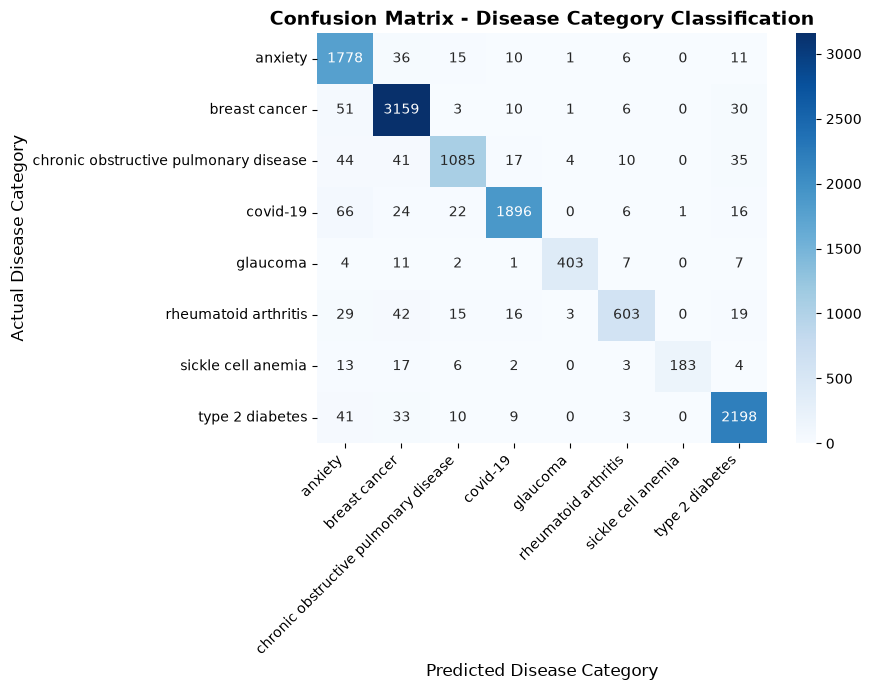

In [10]:
#Compare multiple classification algorithms for performance analysis
#Visualize model performance using evaluation metrics and plots
#confusion matrix heatmap

import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. DEFINE FEATURES (X) AND TARGET (Y)
# ==========================================

# --- FEATURES (X): Numerical representation of cleaned clinical trial summaries ---
print("Extracting Features (X)...")
tfidf_vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X = tfidf_vectorizer.fit_transform(df['cleaned_summary'])
print(f"Feature Matrix Shape (X): {X.shape}")

# --- TARGET (Y): Encoded disease category labels (8 classes) ---
print("Encoding Target (Y)...")
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df['source_condition_query'])
df['target_encoded'] = y

print(f"Target Array Shape (y): {y.shape}")
print("Target Disease Class Mapping:")
for i, label in enumerate(label_encoder.classes_):
    print(f"  Class {i}: {label}")

# ==========================================
# 2. TRAIN-TEST SPLIT
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ==========================================
# 3. COMPARE MULTIPLE ALGORITHMS & TRAIN
# ==========================================
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
}

trained_models = {}
for name, model in models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f"{name} Accuracy: {acc:.4f}")
    trained_models[name] = model

# ==========================================
# 4. VISUALIZE MODEL PERFORMANCE (CONFUSION MATRIX)
# ==========================================
best_model = trained_models["Random Forest"]
y_pred_best = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=label_encoder.classes_, 
            yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix - Disease Category Classification', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Disease Category', fontsize=12)
plt.ylabel('Actual Disease Category', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()